In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [2]:
# =====================================
# 1. Configuration
# =====================================

IMG_SIZE = (224, 224)

BATCH_SIZE = 32

NUM_CLASSES = 2

CLASS_NAMES = ["Cat", "Dog"]

EPOCHS = 30

PATCH_SIZE = 16

PROJECTION_DIM = 64

NUM_HEADS = 4

TRANSFORMER_LAYERS = 4

DROPOUT_RATE = 0.2

LEARNING_RATE = 0.001

SEED = 42

tf.keras.utils.set_random_seed(SEED)

In [3]:
# =====================================
# 2. Load Dataset
# =====================================

FOLDER_SPLIT = Path("PetImages_Split_Clean")

def find_folder(parent, folder_name):

    for folder in parent.iterdir():

        if folder.is_dir() and folder.name.lower() == folder_name.lower():
            return folder

    raise FileNotFoundError(
        f"Folder {folder_name} tidak ditemukan!"
    )


TRAIN_DIR = find_folder(FOLDER_SPLIT, "train")

VALID_DIR = find_folder(FOLDER_SPLIT, "validation")

TEST_DIR = find_folder(FOLDER_SPLIT, "test")


train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)


valid_dataset = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=CLASS_NAMES,
    shuffle=False
)


test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=CLASS_NAMES,
    shuffle=False
)

print("Dataset berhasil dimuat!")

Found 17498 files belonging to 2 classes.
Found 3750 files belonging to 2 classes.
Found 3750 files belonging to 2 classes.
Dataset berhasil dimuat!


In [4]:
# =====================================
# 3. Data Augmentation
# =====================================

data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.05),

    layers.RandomZoom(0.1)

], name="data_augmentation")


AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(AUTOTUNE)

valid_dataset = valid_dataset.prefetch(AUTOTUNE)

test_dataset = test_dataset.prefetch(AUTOTUNE)

In [5]:
# Kode Patches digunakan untuk memecah gambar menjadi potongan-potongan kecil (patch) agar gambar bisa diproses oleh Vision Transformer (ViT).
# =====================================
# 4. Patch Extraction
# =====================================

class Patches(layers.Layer):

    def __init__(self, patch_size):

        super().__init__()

        self.patch_size = patch_size


    def call(self, images):

        patches = tf.image.extract_patches(

            images=images,

            sizes=[
                1,
                self.patch_size,
                self.patch_size,
                1
            ],

            strides=[
                1,
                self.patch_size,
                self.patch_size,
                1
            ],

            rates=[1, 1, 1, 1],

            padding="VALID"
        )

        batch_size = tf.shape(patches)[0]

        patch_dims = patches.shape[-1]

        patches = tf.reshape(
            patches,
            [batch_size, -1, patch_dims]
        )

        return patches

In [6]:
# =====================================
# 5. Patch Encoder
# =====================================

class PatchEncoder(layers.Layer):

    def __init__(self, num_patches, projection_dim):

        super().__init__()

        self.projection = layers.Dense(
            projection_dim
        )

        self.position_embedding = layers.Embedding(
            input_dim=num_patches,
            output_dim=projection_dim
        )

        self.num_patches = num_patches


    def call(self, patches):

        positions = tf.range(
            start=0,
            limit=self.num_patches,
            delta=1
        )

        encoded = self.projection(patches)

        encoded += self.position_embedding(positions)

        return encoded

In [7]:
# =====================================
# 6. Build Vision Transformer
# =====================================

def build_vit_model():

    inputs = layers.Input(
        shape=(*IMG_SIZE, 3)
    )

    # Augmentation
    x = data_augmentation(inputs)

    # Normalization
    x = layers.Rescaling(1./255)(x)

    # Patch Extraction
    patches = Patches(PATCH_SIZE)(x)

    num_patches = (
        IMG_SIZE[0] // PATCH_SIZE
    ) * (
        IMG_SIZE[1] // PATCH_SIZE
    )

    # Patch Embedding
    encoded = PatchEncoder(
        num_patches,
        PROJECTION_DIM
    )(patches)


    # Transformer Encoder
    for _ in range(TRANSFORMER_LAYERS):

        # Layer Normalization
        x1 = layers.LayerNormalization(
            epsilon=1e-6
        )(encoded)

        # Multi Head Self Attention
        attention_output = layers.MultiHeadAttention(

            num_heads=NUM_HEADS,

            key_dim=PROJECTION_DIM // NUM_HEADS,

            dropout=DROPOUT_RATE

        )(x1, x1)

        # Residual Connection
        x2 = layers.Add()([
            encoded,
            attention_output
        ])


        # MLP Block
        x3 = layers.LayerNormalization(
            epsilon=1e-6
        )(x2)

        x3 = layers.Dense(
            PROJECTION_DIM * 2,
            activation="gelu"
        )(x3)

        x3 = layers.Dropout(
            DROPOUT_RATE
        )(x3)

        x3 = layers.Dense(
            PROJECTION_DIM
        )(x3)

        x3 = layers.Dropout(
            DROPOUT_RATE
        )(x3)

        # Residual Connection
        encoded = layers.Add()([
            x2,
            x3
        ])


    # Classification Head
    x = layers.LayerNormalization(
        epsilon=1e-6
    )(encoded)

    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dropout(
        DROPOUT_RATE
    )(x)

    x = layers.Dense(
        128,
        activation="gelu"
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)


    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="Vision_Transformer_Cat_Dog"
    )


    # Compile Model
    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

    return model

In [8]:
# =====================================
# 7. Build Model
# =====================================

model = build_vit_model()

model.summary()

Model: "Vision_Transformer_Cat_Dog"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ data_augmentatio… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches (Patches)   │ (None, None, 768) │          0 │ rescaling[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 196, 64)   │     61,760 │ patches[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 196, 64)   │        128 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 196, 64)   │          0 │ patch_encoder[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 196, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 196, 128)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 196, 64)   │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 196, 64)   │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 196, 64)   │          0 │ add[0][0],        │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 196, 64)   │          0 │ add_1[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 204,354 (798.26 KB)

 Trainable params: 204,354 (798.26 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# =====================================
# 8. Callbacks
# =====================================

callbacks = [

    EarlyStopping(

        monitor="val_loss",

        patience=3,

        restore_best_weights=True

    ),

    ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=2,

        min_lr=1e-7

    ),

    ModelCheckpoint(

        "best_cat_dog_vit.keras",

        monitor="val_loss",

        save_best_only=True

    )

]

In [10]:
# =====================================
# 9. Training Model
# =====================================

history = model.fit(

    train_dataset,

    validation_data=valid_dataset,

    epochs=EPOCHS,

    callbacks=callbacks

)

Epoch 1/30


c:\Users\saire\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


547/547 ━━━━━━━━━━━━━━━━━━━━ 179s 308ms/step - accuracy: 0.5225 - loss: 0.7013 - val_accuracy: 0.5821 - val_loss: 0.6771 - learning_rate: 0.0010
Epoch 2/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 151s 276ms/step - accuracy: 0.5710 - loss: 0.6783 - val_accuracy: 0.5925 - val_loss: 0.6554 - learning_rate: 0.0010
Epoch 3/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 189s 345ms/step - accuracy: 0.5965 - loss: 0.6528 - val_accuracy: 0.6075 - val_loss: 0.6490 - learning_rate: 0.0010
Epoch 4/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 177s 323ms/step - accuracy: 0.6154 - loss: 0.6384 - val_accuracy: 0.6141 - val_loss: 0.6355 - learning_rate: 0.0010
Epoch 5/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 172s 314ms/step - accuracy: 0.6276 - loss: 0.6297 - val_accuracy: 0.6496 - val_loss: 0.6230 - learning_rate: 0.0010
Epoch 6/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 171s 312ms/step - accuracy: 0.6488 - loss: 0.6148 - val_accuracy: 0.6243 - val_loss: 0.6314 - learning_rate: 0.0010
Epoch 7/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 163s 297ms/step - accuracy: 0.6590 

KeyboardInterrupt: 

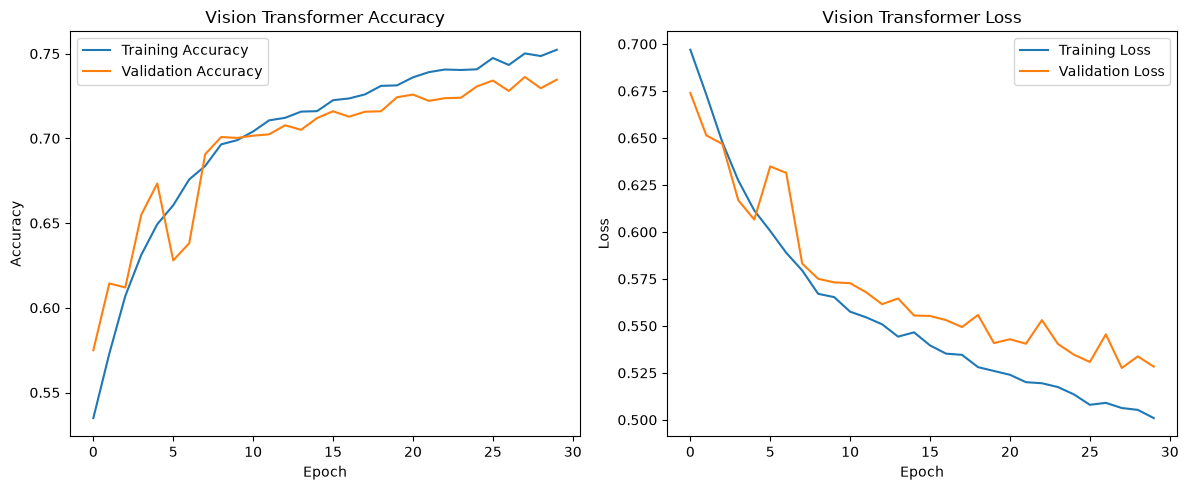

In [ ]:
# =====================================
# 10. Training Visualization
# =====================================

plt.figure(figsize=(12, 5))


# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Vision Transformer Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Vision Transformer Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()


plt.tight_layout()

plt.show()

In [ ]:
# =====================================
# 11. Model Evaluation
# =====================================

test_loss, test_accuracy = model.evaluate(
    test_dataset
)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy)

118/118 ━━━━━━━━━━━━━━━━━━━━ 9s 75ms/step - accuracy: 0.7435 - loss: 0.5041
Test Loss: 0.5040870904922485
Test Accuracy: 0.7434666752815247


In [ ]:
# =====================================
# 12. Classification Report
# =====================================

y_true = np.concatenate([

    labels.numpy()

    for images, labels in test_dataset

])


y_pred_prob = model.predict(test_dataset)


y_pred = np.argmax(
    y_pred_prob,
    axis=1
)


print(
    classification_report(

        y_true,

        y_pred,

        target_names=CLASS_NAMES

    )
)

118/118 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step
              precision    recall  f1-score   support

         Cat       0.72      0.79      0.75      1875
         Dog       0.77      0.70      0.73      1875

    accuracy                           0.74      3750
   macro avg       0.75      0.74      0.74      3750
weighted avg       0.75      0.74      0.74      3750



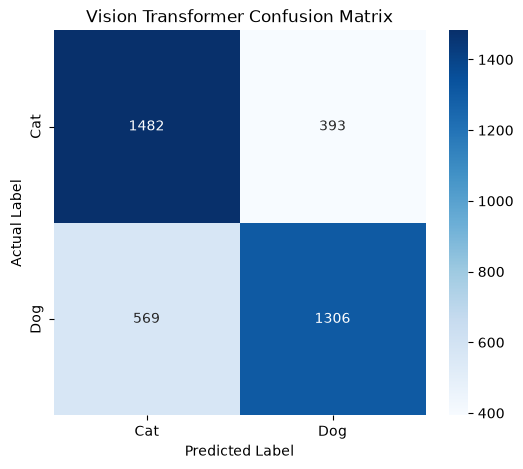

In [ ]:
# =====================================
# 13. Confusion Matrix
# =====================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=CLASS_NAMES,

    yticklabels=CLASS_NAMES

)

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.title("Vision Transformer Confusion Matrix")

plt.show()

Vision Transformer Model Saved!
